# ZeroSyl syllable-boundary performance evaluation

This notebook compares a ZeroSyl-estimated Praat `TextGrid` against a manually annotated ground-truth `TextGrid`.

It calculates:

- **True positives (TP):** estimated boundaries matched to a ground-truth boundary within the tolerance.
- **False positives (FP):** estimated boundaries that remain unmatched.
- **False negatives (FN):** ground-truth boundaries that remain unmatched.
- **Precision, recall, F1 score**, and timing-error statistics.

## Important matching rule

Matching is strictly **one-to-one**. A ground-truth boundary and an estimated boundary can each be used only once. Therefore, when two ZeroSyl boundaries fall inside the tolerance window of one ground-truth boundary, only one can be a TP; the other remains an FP unless it can validly match another ground-truth boundary.

The notebook uses dynamic programming to:

1. maximize the number of valid one-to-one matches; and
2. among solutions with the same TP count, minimize total absolute timing error.

The beginning and end of the entire recording are excluded because they are file limits rather than detected internal boundaries.


In [5]:
from pathlib import Path
from functools import reduce
from math import gcd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")


## 1. Configuration

Change `TOLERANCE_MS` and rerun from this cell downward.

A default of **50 ms** is used because the supplied ZeroSyl boundaries lie on a 20 ms time grid. A 50 ms window therefore allows about 2.5 ZeroSyl frames for frame quantization and modest annotation-placement variation, while remaining much smaller than the median spacing between ground-truth boundaries in this recording.

The tolerance is an evaluation choice rather than a fixed property of the program. A later section plots performance over a range of tolerances so that results can be reported transparently.

`BOUNDARY_MODE = "all_internal"` evaluates every internal interval transition in the syllable tier. For the supplied files, this is also equivalent to collecting every non-empty syllable onset and offset, because every internal transition touches a non-empty interval.


In [7]:
# File names may be edited here.
GROUND_TRUTH_FILE = Path("id_3_main_post_test_syllables.TextGrid")
ESTIMATE_FILE = Path("ZeroSyl_id_3_main_post_test_syllables.TextGrid")


GROUND_TRUTH_TIER = "syllables"
ESTIMATE_TIER = "syllables"

# Main user-adjustable evaluation parameter:
TOLERANCE_MS = 50.0

# Options:
#   "all_internal"      = every internal transition in the chosen tier
#   "syllable_edges"    = onset/offset of every non-empty syllable interval
#   "between_syllables" = only transitions with non-empty syllables on both sides
BOUNDARY_MODE = "all_internal"

# Set to True only when the recording start and end should be scored as detections.
INCLUDE_RECORDING_ENDPOINTS = False

# The uploaded copies used to build this notebook had "(2)" appended.
# This helper finds such copies automatically if the exact configured name is absent.
def resolve_file(configured_path: Path) -> Path:
    configured_path = Path(configured_path)
    if configured_path.exists():
        return configured_path

    parent = configured_path.parent if str(configured_path.parent) not in ("", ".") else Path(".")
    candidates = sorted(parent.glob(f"{configured_path.stem}*{configured_path.suffix}"))

    # Also support execution in ChatGPT's /mnt/data environment.
    if not candidates:
        candidates = sorted(Path("/mnt/data").glob(f"{configured_path.stem}*{configured_path.suffix}"))

    if not candidates:
        raise FileNotFoundError(
            f"Could not find {configured_path}. Put the TextGrid beside the notebook "
            "or change the path in the configuration cell."
        )
    return candidates[0]

GROUND_TRUTH_FILE = resolve_file(GROUND_TRUTH_FILE)
ESTIMATE_FILE = resolve_file(ESTIMATE_FILE)

print("Ground truth:", GROUND_TRUTH_FILE.resolve())
print("Estimate:    ", ESTIMATE_FILE.resolve())
print(f"Tolerance:   ±{TOLERANCE_MS:.1f} ms")


Ground truth: /home/hendrik/Skripsie/JupyterNotebooks/id_3_main_post_test_syllables.TextGrid
Estimate:     /home/hendrik/Skripsie/JupyterNotebooks/ZeroSyl_id_3_main_post_test_syllables.TextGrid
Tolerance:   ±50.0 ms


## 2. Dependency-free Praat TextGrid parser

This parser reads the normal long-text Praat `TextGrid` format used by the supplied files. No Praat-specific Python package is required.


In [8]:
import re

_NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"

def _unescape_praat_string(value: str) -> str:
    # Praat represents a quote inside a quoted string by doubling it.
    return value.replace('""', '"')

def parse_long_textgrid(path):
    path = Path(path)
    raw = path.read_text(encoding="utf-8", errors="replace")

    item_matches = list(re.finditer(r"(?m)^\s*item\s*\[(\d+)\]:\s*$", raw))
    if not item_matches:
        raise ValueError(
            f"No tiers were found in {path}. This parser expects Praat's long-text TextGrid format."
        )

    tiers = {}
    for item_pos, item_match in enumerate(item_matches):
        start = item_match.end()
        end = item_matches[item_pos + 1].start() if item_pos + 1 < len(item_matches) else len(raw)
        block = raw[start:end]

        class_match = re.search(r'(?m)^\s*class\s*=\s*"([^"]*)"\s*$', block)
        name_match = re.search(r'(?m)^\s*name\s*=\s*"([^"]*)"\s*$', block)
        if class_match is None or name_match is None:
            continue

        tier_class = class_match.group(1)
        tier_name = _unescape_praat_string(name_match.group(1))

        tier_xmin_match = re.search(rf"(?m)^\s*xmin\s*=\s*({_NUMBER})\s*$", block)
        tier_xmax_match = re.search(rf"(?m)^\s*xmax\s*=\s*({_NUMBER})\s*$", block)

        tier = {
            "name": tier_name,
            "class": tier_class,
            "xmin": float(tier_xmin_match.group(1)) if tier_xmin_match else np.nan,
            "xmax": float(tier_xmax_match.group(1)) if tier_xmax_match else np.nan,
        }

        if tier_class == "IntervalTier":
            interval_matches = list(
                re.finditer(r"(?m)^\s*intervals\s*\[(\d+)\]:\s*$", block)
            )
            intervals = []
            for interval_pos, interval_match in enumerate(interval_matches):
                interval_start = interval_match.end()
                interval_end = (
                    interval_matches[interval_pos + 1].start()
                    if interval_pos + 1 < len(interval_matches)
                    else len(block)
                )
                interval_block = block[interval_start:interval_end]

                xmin_match = re.search(
                    rf"(?m)^\s*xmin\s*=\s*({_NUMBER})\s*$", interval_block
                )
                xmax_match = re.search(
                    rf"(?m)^\s*xmax\s*=\s*({_NUMBER})\s*$", interval_block
                )
                text_match = re.search(
                    r'(?m)^\s*text\s*=\s*"(.*)"\s*$', interval_block
                )

                if xmin_match is None or xmax_match is None:
                    raise ValueError(
                        f"Malformed interval {interval_pos + 1} in tier {tier_name!r}."
                    )

                intervals.append(
                    {
                        "xmin": float(xmin_match.group(1)),
                        "xmax": float(xmax_match.group(1)),
                        "text": _unescape_praat_string(text_match.group(1))
                        if text_match
                        else "",
                    }
                )
            tier["intervals"] = intervals

        elif tier_class == "TextTier":
            point_matches = list(
                re.finditer(r"(?m)^\s*points\s*\[(\d+)\]:\s*$", block)
            )
            points = []
            for point_pos, point_match in enumerate(point_matches):
                point_start = point_match.end()
                point_end = (
                    point_matches[point_pos + 1].start()
                    if point_pos + 1 < len(point_matches)
                    else len(block)
                )
                point_block = block[point_start:point_end]
                number_match = re.search(
                    rf"(?m)^\s*number\s*=\s*({_NUMBER})\s*$", point_block
                )
                mark_match = re.search(
                    r'(?m)^\s*mark\s*=\s*"(.*)"\s*$', point_block
                )
                if number_match:
                    points.append(
                        {
                            "time": float(number_match.group(1)),
                            "mark": _unescape_praat_string(mark_match.group(1))
                            if mark_match
                            else "",
                        }
                    )
            tier["points"] = points

        tiers[tier_name] = tier

    if not tiers:
        raise ValueError(f"No readable tiers were found in {path}.")
    return tiers

ground_truth_tiers = parse_long_textgrid(GROUND_TRUTH_FILE)
estimate_tiers = parse_long_textgrid(ESTIMATE_FILE)

def tier_summary(tiers):
    rows = []
    for name, tier in tiers.items():
        if tier["class"] == "IntervalTier":
            count = len(tier.get("intervals", []))
        else:
            count = len(tier.get("points", []))
        rows.append(
            {
                "tier": name,
                "class": tier["class"],
                "items": count,
                "xmin_s": tier["xmin"],
                "xmax_s": tier["xmax"],
            }
        )
    return pd.DataFrame(rows)

print("Ground-truth tiers")
display(tier_summary(ground_truth_tiers))
print("\nEstimated tiers")
display(tier_summary(estimate_tiers))


Ground-truth tiers


,tier,class,items,xmin_s,xmax_s
0,words,IntervalTier,257,0.0,75.762
1,phones,IntervalTier,585,0.0,75.762
2,syllables,IntervalTier,295,0.0,75.762



Estimated tiers


,tier,class,items,xmin_s,xmax_s
0,syllables,IntervalTier,274,0.0,75.76


## 3. Extract syllable boundaries

For an `IntervalTier`, all boundary times are deduplicated and sorted.

- `all_internal`: every transition between adjacent tier intervals.
- `syllable_edges`: every onset and offset belonging to a non-empty interval.
- `between_syllables`: only a shared edge where both adjacent intervals are non-empty.

For a `TextTier`, each point is treated directly as a boundary.


In [9]:
def extract_boundaries(
    tier,
    mode="all_internal",
    include_recording_endpoints=False,
):
    if tier["class"] == "TextTier":
        boundaries = sorted({float(point["time"]) for point in tier.get("points", [])})
        return np.asarray(boundaries, dtype=float)

    if tier["class"] != "IntervalTier":
        raise ValueError(f"Unsupported tier class: {tier['class']}")

    intervals = tier.get("intervals", [])
    if not intervals:
        return np.asarray([], dtype=float)

    recording_start = min(interval["xmin"] for interval in intervals)
    recording_end = max(interval["xmax"] for interval in intervals)

    if mode == "all_internal":
        boundaries = {
            value
            for interval in intervals
            for value in (interval["xmin"], interval["xmax"])
        }

    elif mode == "syllable_edges":
        boundaries = set()
        for interval in intervals:
            if interval["text"].strip():
                boundaries.add(interval["xmin"])
                boundaries.add(interval["xmax"])

    elif mode == "between_syllables":
        boundaries = set()
        for left, right in zip(intervals[:-1], intervals[1:]):
            if left["text"].strip() and right["text"].strip():
                # Use the shared transition time. The average is robust to tiny
                # floating-point disagreement between left xmax and right xmin.
                boundaries.add((left["xmax"] + right["xmin"]) / 2.0)
    else:
        raise ValueError(
            "mode must be 'all_internal', 'syllable_edges', or 'between_syllables'"
        )

    if not include_recording_endpoints:
        eps = 1e-9
        boundaries = {
            time
            for time in boundaries
            if time > recording_start + eps and time < recording_end - eps
        }

    return np.asarray(sorted(boundaries), dtype=float)

if GROUND_TRUTH_TIER not in ground_truth_tiers:
    raise KeyError(
        f"Ground-truth tier {GROUND_TRUTH_TIER!r} not found. "
        f"Available tiers: {list(ground_truth_tiers)}"
    )
if ESTIMATE_TIER not in estimate_tiers:
    raise KeyError(
        f"Estimated tier {ESTIMATE_TIER!r} not found. "
        f"Available tiers: {list(estimate_tiers)}"
    )

ground_truth_boundaries = extract_boundaries(
    ground_truth_tiers[GROUND_TRUTH_TIER],
    mode=BOUNDARY_MODE,
    include_recording_endpoints=INCLUDE_RECORDING_ENDPOINTS,
)
estimated_boundaries = extract_boundaries(
    estimate_tiers[ESTIMATE_TIER],
    mode=BOUNDARY_MODE,
    include_recording_endpoints=INCLUDE_RECORDING_ENDPOINTS,
)

print(f"Boundary mode: {BOUNDARY_MODE}")
print(f"Ground-truth boundaries: {len(ground_truth_boundaries)}")
print(f"Estimated boundaries:    {len(estimated_boundaries)}")
print("First 10 ground-truth boundaries:", ground_truth_boundaries[:10])
print("First 10 estimated boundaries:   ", estimated_boundaries[:10])


Boundary mode: all_internal
Ground-truth boundaries: 294
Estimated boundaries:    273
First 10 ground-truth boundaries: [0.08 0.3  0.87 1.1  1.26 1.97 2.1  2.59 2.77 2.82]
First 10 estimated boundaries:    [0.1  0.32 0.84 1.08 1.28 1.66 1.98 2.22 2.52 2.64]


## 4. Timing-resolution diagnostics and tolerance rationale

The estimated timestamp grid is inferred from the data by converting timestamps to microseconds and taking their greatest common divisor. The spacing statistics help place the chosen tolerance in context.


In [10]:
def infer_timestamp_grid_seconds(times, decimal_places=6):
    times = np.asarray(times, dtype=float)
    if len(times) < 2:
        return np.nan
    scale = 10 ** decimal_places
    integer_times = np.rint(times * scale).astype(np.int64)
    positive_differences = np.diff(np.unique(integer_times))
    positive_differences = positive_differences[positive_differences > 0]
    if len(positive_differences) == 0:
        return np.nan
    grid_integer = reduce(gcd, positive_differences.tolist())
    return grid_integer / scale

def spacing_summary_ms(times):
    times = np.asarray(times, dtype=float)
    spacings_ms = np.diff(times) * 1000.0
    if len(spacings_ms) == 0:
        return pd.Series(dtype=float)
    return pd.Series(
        {
            "minimum": np.min(spacings_ms),
            "10th percentile": np.percentile(spacings_ms, 10),
            "median": np.median(spacings_ms),
            "90th percentile": np.percentile(spacings_ms, 90),
            "maximum": np.max(spacings_ms),
        }
    )

estimated_grid_s = infer_timestamp_grid_seconds(estimated_boundaries)
print(f"Inferred ZeroSyl timestamp grid: {estimated_grid_s * 1000:.1f} ms")
print(
    f"Chosen tolerance: {TOLERANCE_MS:.1f} ms "
    f"({TOLERANCE_MS / (estimated_grid_s * 1000):.2f} estimated frames)"
)

diagnostics = pd.DataFrame(
    {
        "ground_truth_spacing_ms": spacing_summary_ms(ground_truth_boundaries),
        "estimated_spacing_ms": spacing_summary_ms(estimated_boundaries),
    }
)
display(diagnostics.round(3))

print(
    "\nRationale: 50 ms accommodates the 20 ms output grid plus modest manual "
    "annotation variation. It is still substantially below the median "
    "ground-truth boundary spacing shown above. Because matching is one-to-one, "
    "overlapping tolerance windows cannot double-count a boundary."
)


Inferred ZeroSyl timestamp grid: 20.0 ms
Chosen tolerance: 50.0 ms (2.50 estimated frames)


,ground_truth_spacing_ms,estimated_spacing_ms
minimum,29.999,80.0
10th percentile,80.000,160.0
median,200.000,240.0
90th percentile,538.000,440.0
maximum,1189.999,1120.0



Rationale: 50 ms accommodates the 20 ms output grid plus modest manual annotation variation. It is still substantially below the median ground-truth boundary spacing shown above. Because matching is one-to-one, overlapping tolerance windows cannot double-count a boundary.


## 5. One-to-one optimal boundary matching

The dynamic-programming table compares the first `i` ground-truth boundaries with the first `j` estimated boundaries.

At every position it may:

- leave the current ground-truth boundary unmatched;
- leave the current estimated boundary unmatched; or
- match them when their absolute difference is within the tolerance.

The objective is lexicographic: **maximize TP count first**, then **minimize total absolute error**.


In [11]:
def _candidate_is_better(candidate, current, eps=1e-12):
    # candidate/current = (number_of_matches, total_error, priority, action)
    if candidate[0] != current[0]:
        return candidate[0] > current[0]
    if abs(candidate[1] - current[1]) > eps:
        return candidate[1] < current[1]
    # Deterministic tie break: prefer a match over a skip.
    return candidate[2] > current[2]

def match_boundaries_one_to_one(ground_truth, estimated, tolerance_s):
    ground_truth = np.asarray(ground_truth, dtype=float)
    estimated = np.asarray(estimated, dtype=float)

    if tolerance_s < 0:
        raise ValueError("tolerance_s must be non-negative")

    n_ground_truth = len(ground_truth)
    n_estimated = len(estimated)

    match_count = np.zeros((n_ground_truth + 1, n_estimated + 1), dtype=np.int32)
    total_error = np.zeros((n_ground_truth + 1, n_estimated + 1), dtype=float)
    backpointer = np.zeros((n_ground_truth + 1, n_estimated + 1), dtype=np.int8)

    # Actions: 1 = skip GT, 2 = skip estimate, 3 = match.
    backpointer[1:, 0] = 1
    backpointer[0, 1:] = 2

    for i in range(1, n_ground_truth + 1):
        for j in range(1, n_estimated + 1):
            candidates = [
                (
                    match_count[i - 1, j],
                    total_error[i - 1, j],
                    0,
                    1,
                ),
                (
                    match_count[i, j - 1],
                    total_error[i, j - 1],
                    0,
                    2,
                ),
            ]

            difference = abs(ground_truth[i - 1] - estimated[j - 1])
            if difference <= tolerance_s + 1e-12:
                candidates.append(
                    (
                        match_count[i - 1, j - 1] + 1,
                        total_error[i - 1, j - 1] + difference,
                        2,
                        3,
                    )
                )

            best = candidates[0]
            for candidate in candidates[1:]:
                if _candidate_is_better(candidate, best):
                    best = candidate

            match_count[i, j] = best[0]
            total_error[i, j] = best[1]
            backpointer[i, j] = best[3]

    matches = []
    i, j = n_ground_truth, n_estimated
    while i > 0 or j > 0:
        action = backpointer[i, j]

        if action == 3:
            ground_truth_index = i - 1
            estimated_index = j - 1
            signed_error_s = (
                estimated[estimated_index] - ground_truth[ground_truth_index]
            )
            matches.append(
                {
                    "ground_truth_index": ground_truth_index,
                    "ground_truth_time_s": ground_truth[ground_truth_index],
                    "estimated_index": estimated_index,
                    "estimated_time_s": estimated[estimated_index],
                    "signed_error_ms": signed_error_s * 1000.0,
                    "absolute_error_ms": abs(signed_error_s) * 1000.0,
                }
            )
            i -= 1
            j -= 1

        elif action == 1:
            i -= 1
        elif action == 2:
            j -= 1
        else:
            raise RuntimeError("Invalid backpointer encountered during matching.")

    matches.reverse()

    matched_ground_truth = {row["ground_truth_index"] for row in matches}
    matched_estimates = {row["estimated_index"] for row in matches}

    false_negative_indices = [
        index
        for index in range(n_ground_truth)
        if index not in matched_ground_truth
    ]
    false_positive_indices = [
        index
        for index in range(n_estimated)
        if index not in matched_estimates
    ]

    return matches, false_negative_indices, false_positive_indices

# Regression tests for the no-double-counting requirement.
_test_matches, _test_fn, _test_fp = match_boundaries_one_to_one(
    ground_truth=[1.000],
    estimated=[0.980, 1.020],
    tolerance_s=0.050,
)
assert len(_test_matches) == 1
assert len(_test_fn) == 0
assert len(_test_fp) == 1

# This case defeats a naïve globally-nearest greedy matcher, but the optimal
# one-to-one algorithm correctly finds two matches.
_test_matches, _test_fn, _test_fp = match_boundaries_one_to_one(
    ground_truth=[0.000, 0.110],
    estimated=[0.100, 0.210],
    tolerance_s=0.110,
)
assert len(_test_matches) == 2
assert len(_test_fn) == 0
assert len(_test_fp) == 0

print("One-to-one matching tests passed.")


One-to-one matching tests passed.


## 6. Evaluate ZeroSyl

Change the tolerance in the configuration cell and rerun from there to obtain a new evaluation.


In [12]:
def nearest_time_and_error(query_time, reference_times):
    reference_times = np.asarray(reference_times, dtype=float)
    if len(reference_times) == 0:
        return np.nan, np.nan
    position = np.searchsorted(reference_times, query_time)
    candidate_indices = {
        max(0, min(len(reference_times) - 1, position - 1)),
        max(0, min(len(reference_times) - 1, position)),
    }
    nearest_index = min(
        candidate_indices,
        key=lambda index: abs(reference_times[index] - query_time),
    )
    nearest_time = reference_times[nearest_index]
    return nearest_time, abs(nearest_time - query_time) * 1000.0

def evaluate_boundaries(ground_truth, estimated, tolerance_ms):
    tolerance_s = tolerance_ms / 1000.0
    matches, false_negative_indices, false_positive_indices = (
        match_boundaries_one_to_one(
            ground_truth=ground_truth,
            estimated=estimated,
            tolerance_s=tolerance_s,
        )
    )

    matches_df = pd.DataFrame(matches)

    false_negatives = []
    for index in false_negative_indices:
        nearest_time, nearest_error_ms = nearest_time_and_error(
            ground_truth[index], estimated
        )
        false_negatives.append(
            {
                "ground_truth_index": index,
                "ground_truth_time_s": ground_truth[index],
                "nearest_estimated_time_s": nearest_time,
                "nearest_absolute_error_ms": nearest_error_ms,
            }
        )
    false_negatives_df = pd.DataFrame(false_negatives)

    false_positives = []
    for index in false_positive_indices:
        nearest_time, nearest_error_ms = nearest_time_and_error(
            estimated[index], ground_truth
        )
        false_positives.append(
            {
                "estimated_index": index,
                "estimated_time_s": estimated[index],
                "nearest_ground_truth_time_s": nearest_time,
                "nearest_absolute_error_ms": nearest_error_ms,
            }
        )
    false_positives_df = pd.DataFrame(false_positives)

    true_positives = len(matches)
    false_negatives_count = len(false_negative_indices)
    false_positives_count = len(false_positive_indices)

    precision = (
        true_positives / (true_positives + false_positives_count)
        if true_positives + false_positives_count
        else np.nan
    )
    recall = (
        true_positives / (true_positives + false_negatives_count)
        if true_positives + false_negatives_count
        else np.nan
    )
    f1 = (
        2 * precision * recall / (precision + recall)
        if np.isfinite(precision)
        and np.isfinite(recall)
        and precision + recall > 0
        else np.nan
    )

    absolute_errors = (
        matches_df["absolute_error_ms"].to_numpy()
        if not matches_df.empty
        else np.asarray([])
    )

    summary = pd.Series(
        {
            "tolerance_ms": tolerance_ms,
            "ground_truth_boundaries": len(ground_truth),
            "estimated_boundaries": len(estimated),
            "true_positives": true_positives,
            "false_positives": false_positives_count,
            "false_negatives": false_negatives_count,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "mean_absolute_error_ms": (
                np.mean(absolute_errors) if len(absolute_errors) else np.nan
            ),
            "median_absolute_error_ms": (
                np.median(absolute_errors) if len(absolute_errors) else np.nan
            ),
            "maximum_absolute_error_ms": (
                np.max(absolute_errors) if len(absolute_errors) else np.nan
            ),
        },
        name="value",
    )

    return {
        "summary": summary,
        "matches": matches_df,
        "false_negatives": false_negatives_df,
        "false_positives": false_positives_df,
    }

results = evaluate_boundaries(
    ground_truth=ground_truth_boundaries,
    estimated=estimated_boundaries,
    tolerance_ms=TOLERANCE_MS,
)

summary_table = results["summary"].to_frame()
display(
    summary_table.style.format(
        {
            "value": lambda value: (
                f"{value:.4f}" if isinstance(value, (float, np.floating)) else str(value)
            )
        }
    )
)

print(
    f"\nAt ±{TOLERANCE_MS:.1f} ms: "
    f"TP={int(results['summary']['true_positives'])}, "
    f"FP={int(results['summary']['false_positives'])}, "
    f"FN={int(results['summary']['false_negatives'])}, "
    f"F1={results['summary']['f1_score']:.3f}"
)


,value
tolerance_ms,50.0000
ground_truth_boundaries,294.0000
estimated_boundaries,273.0000
true_positives,164.0000
false_positives,109.0000
false_negatives,130.0000
precision,0.6007
recall,0.5578
f1_score,0.5785
mean_absolute_error_ms,23.9427



At ±50.0 ms: TP=164, FP=109, FN=130, F1=0.578


## 7. Detailed TP, FP, and FN tables

The TP table records the exact matched pair and timing error. The FP and FN tables include the closest boundary on the opposite side for diagnosis, even though that closest boundary was not a valid unused match.


In [13]:
print("TRUE POSITIVES / MATCHED PAIRS")
display(results["matches"].round(4))

print("\nFALSE POSITIVES / UNMATCHED ZEROSYL BOUNDARIES")
display(results["false_positives"].round(4))

print("\nFALSE NEGATIVES / UNMATCHED GROUND-TRUTH BOUNDARIES")
display(results["false_negatives"].round(4))


TRUE POSITIVES / MATCHED PAIRS


,ground_truth_index,ground_truth_time_s,estimated_index,estimated_time_s,signed_error_ms,absolute_error_ms
0,0,0.080,0,0.10,20.000,20.000
1,1,0.300,1,0.32,20.000,20.000
2,2,0.870,2,0.84,-30.000,30.000
3,3,1.100,3,1.08,-20.000,20.000
4,4,1.260,4,1.28,20.000,20.000
...,...,...,...,...,...,...
159,280,71.795,260,71.80,5.002,5.002
160,282,72.685,263,72.68,-4.998,4.998
161,285,73.505,265,73.46,-44.997,44.997
162,287,73.765,266,73.76,-4.999,4.999



FALSE POSITIVES / UNMATCHED ZEROSYL BOUNDARIES


,estimated_index,estimated_time_s,nearest_ground_truth_time_s,nearest_absolute_error_ms
0,5,1.66,1.970,310.000
1,7,2.22,2.100,120.000
2,8,2.52,2.590,70.000
3,12,3.24,3.300,60.000
4,13,3.44,3.300,140.000
...,...,...,...,...
104,268,74.40,74.335,65.001
105,269,74.66,74.715,55.004
106,270,75.04,75.115,74.998
107,271,75.26,75.115,145.002



FALSE NEGATIVES / UNMATCHED GROUND-TRUTH BOUNDARIES


,ground_truth_index,ground_truth_time_s,nearest_estimated_time_s,nearest_absolute_error_ms
0,6,2.1000,1.98,120.000
1,8,2.7700,2.82,50.000
2,11,3.3000,3.24,60.000
3,12,3.6098,3.44,169.800
4,13,3.8398,3.94,100.200
...,...,...,...,...
125,288,73.9250,74.00,74.997
126,290,74.3350,74.40,65.001
127,291,74.7150,74.66,55.004
128,292,74.8650,75.04,175.002


## 8. Full-recording visualization

- **Blue vertical lines:** all ground-truth boundaries.
- **Green circles:** matched ZeroSyl boundaries (TP).
- **Red crosses:** unmatched ZeroSyl boundaries (FP).
- **Orange triangles:** unmatched ground-truth boundaries (FN).

The full plot is useful for the overall distribution. The zoomed plot in the next section shows tolerance windows and pair connections more clearly.


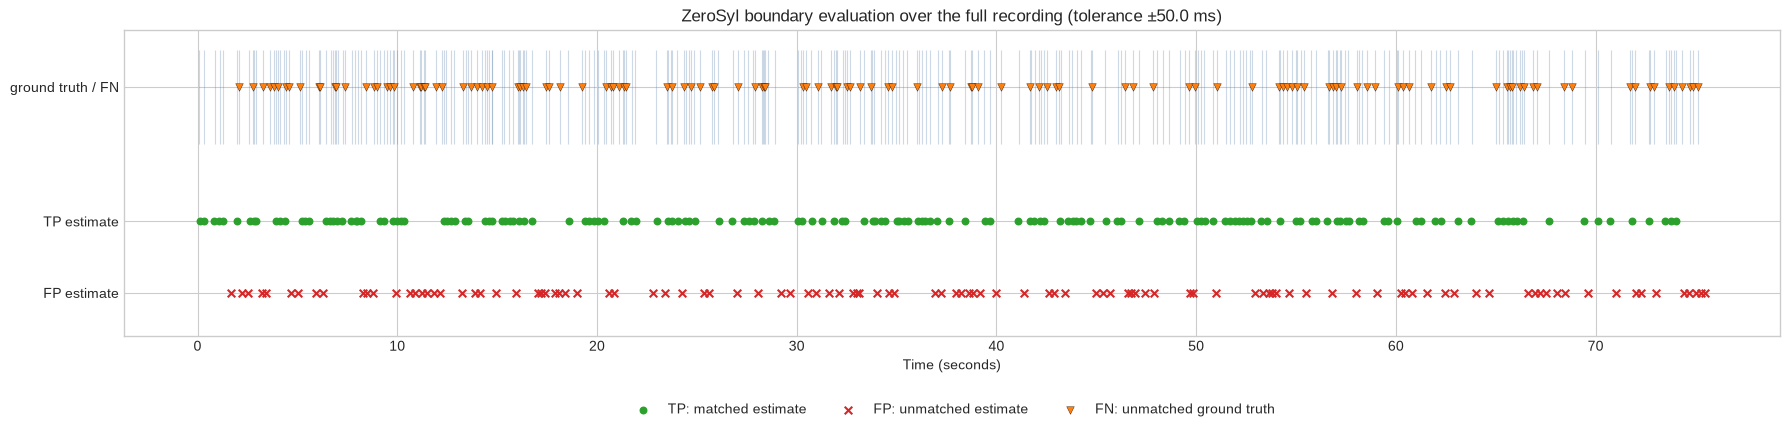

In [14]:
def plot_full_evaluation(
    ground_truth,
    estimated,
    evaluation_results,
    figsize=(18, 4.5),
):
    matches = evaluation_results["matches"]
    false_negatives = evaluation_results["false_negatives"]
    false_positives = evaluation_results["false_positives"]

    fig, ax = plt.subplots(figsize=figsize)

    for time in ground_truth:
        ax.vlines(time, 0.72, 1.05, color="#4C78A8", alpha=0.28, linewidth=0.8)

    if not matches.empty:
        ax.scatter(
            matches["estimated_time_s"],
            np.full(len(matches), 0.45),
            color="#2CA02C",
            s=22,
            marker="o",
            label="TP: matched estimate",
            zorder=4,
        )

    if not false_positives.empty:
        ax.scatter(
            false_positives["estimated_time_s"],
            np.full(len(false_positives), 0.20),
            color="#D62728",
            s=30,
            marker="x",
            label="FP: unmatched estimate",
            zorder=5,
        )

    if not false_negatives.empty:
        ax.scatter(
            false_negatives["ground_truth_time_s"],
            np.full(len(false_negatives), 0.92),
            color="#FF7F0E",
            edgecolor="black",
            linewidth=0.25,
            s=30,
            marker="v",
            label="FN: unmatched ground truth",
            zorder=5,
        )

    ax.set_ylim(0.05, 1.12)
    ax.set_yticks([0.20, 0.45, 0.92])
    ax.set_yticklabels(["FP estimate", "TP estimate", "ground truth / FN"])
    ax.set_xlabel("Time (seconds)")
    ax.set_title(
        f"ZeroSyl boundary evaluation over the full recording "
        f"(tolerance ±{evaluation_results['summary']['tolerance_ms']:.1f} ms)"
    )
    ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.18))
    plt.tight_layout()
    plt.show()

plot_full_evaluation(
    ground_truth_boundaries,
    estimated_boundaries,
    results,
)


## 9. Zoomed visualization with tolerance windows

Edit `WINDOW_START_S` and `WINDOW_END_S` to inspect any part of the recording.

Each light-blue band is the allowed tolerance range around a ground-truth boundary. Green connecting lines show the exact one-to-one TP assignment.


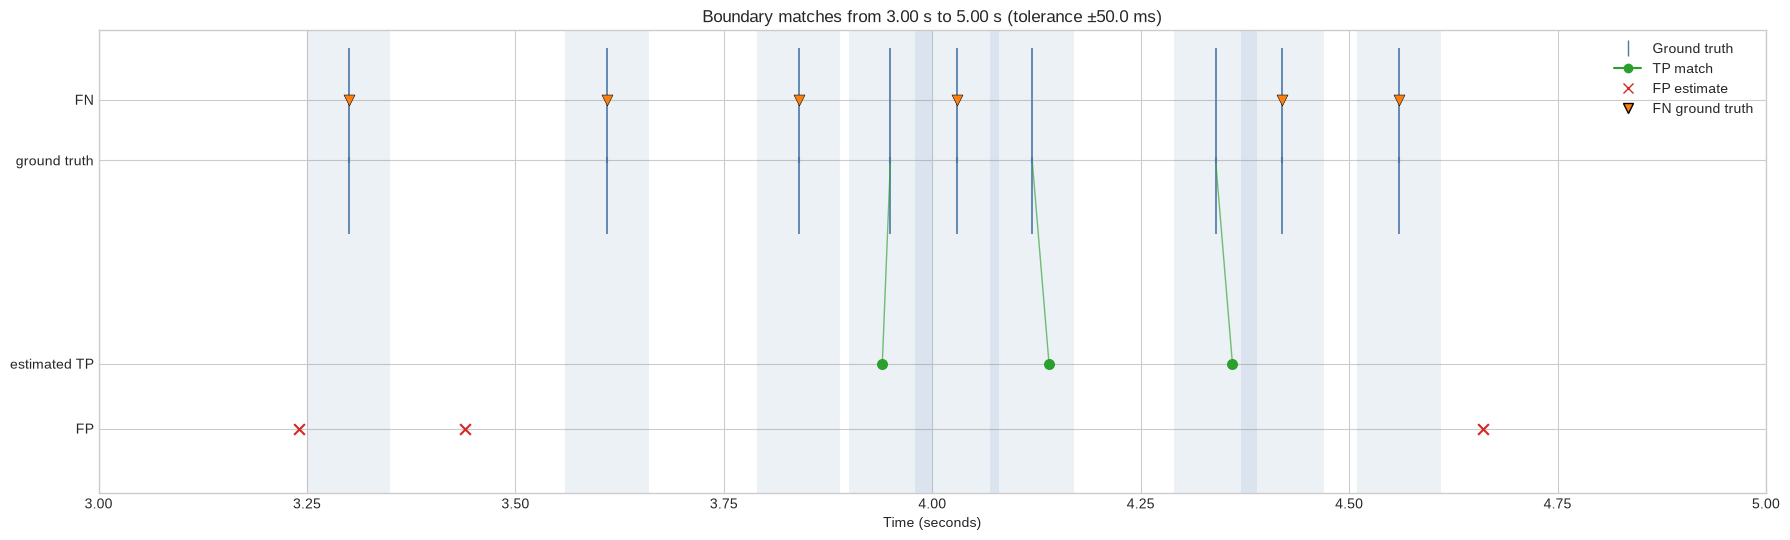

In [17]:
WINDOW_START_S = 3.0
WINDOW_END_S = 5.0

def plot_evaluation_window(
    ground_truth,
    estimated,
    evaluation_results,
    start_s,
    end_s,
    figsize=(18, 5.5),
):
    if end_s <= start_s:
        raise ValueError("end_s must be greater than start_s")

    tolerance_s = evaluation_results["summary"]["tolerance_ms"] / 1000.0
    matches = evaluation_results["matches"]
    false_negatives = evaluation_results["false_negatives"]
    false_positives = evaluation_results["false_positives"]

    fig, ax = plt.subplots(figsize=figsize)

    visible_ground_truth = ground_truth[
        (ground_truth >= start_s) & (ground_truth <= end_s)
    ]
    visible_estimated = estimated[
        (estimated >= start_s) & (estimated <= end_s)
    ]

    for time in visible_ground_truth:
        ax.axvspan(
            time - tolerance_s,
            time + tolerance_s,
            color="#4C78A8",
            alpha=0.10,
            linewidth=0,
        )
        ax.vlines(time, 0.65, 1.08, color="#4C78A8", linewidth=1.2)

    visible_matches = matches[
        (matches["ground_truth_time_s"] >= start_s - tolerance_s)
        & (matches["ground_truth_time_s"] <= end_s + tolerance_s)
        & (matches["estimated_time_s"] >= start_s - tolerance_s)
        & (matches["estimated_time_s"] <= end_s + tolerance_s)
    ]

    for row in visible_matches.itertuples(index=False):
        ax.plot(
            [row.ground_truth_time_s, row.estimated_time_s],
            [0.82, 0.35],
            color="#2CA02C",
            alpha=0.65,
            linewidth=1.0,
            zorder=3,
        )

    if not visible_matches.empty:
        ax.scatter(
            visible_matches["estimated_time_s"],
            np.full(len(visible_matches), 0.35),
            color="#2CA02C",
            s=48,
            marker="o",
            zorder=5,
        )

    visible_fp = false_positives[
        (false_positives["estimated_time_s"] >= start_s)
        & (false_positives["estimated_time_s"] <= end_s)
    ]
    if not visible_fp.empty:
        ax.scatter(
            visible_fp["estimated_time_s"],
            np.full(len(visible_fp), 0.20),
            color="#D62728",
            s=60,
            marker="x",
            linewidth=1.5,
            zorder=6,
        )

    visible_fn = false_negatives[
        (false_negatives["ground_truth_time_s"] >= start_s)
        & (false_negatives["ground_truth_time_s"] <= end_s)
    ]
    if not visible_fn.empty:
        ax.scatter(
            visible_fn["ground_truth_time_s"],
            np.full(len(visible_fn), 0.96),
            color="#FF7F0E",
            edgecolor="black",
            linewidth=0.4,
            s=62,
            marker="v",
            zorder=6,
        )

    ax.scatter(
        visible_ground_truth,
        np.full(len(visible_ground_truth), 0.82),
        color="#4C78A8",
        s=20,
        marker="|",
        linewidth=1.5,
        zorder=4,
    )

    ax.set_xlim(start_s, end_s)
    ax.set_ylim(0.05, 1.12)
    ax.set_yticks([0.20, 0.35, 0.82, 0.96])
    ax.set_yticklabels(["FP", "estimated TP", "ground truth", "FN"])
    ax.set_xlabel("Time (seconds)")
    ax.set_title(
        f"Boundary matches from {start_s:.2f} s to {end_s:.2f} s "
        f"(tolerance ±{evaluation_results['summary']['tolerance_ms']:.1f} ms)"
    )

    legend_handles = [
        Line2D([0], [0], color="#4C78A8", marker="|", linestyle="None",
               markersize=12, label="Ground truth"),
        Line2D([0], [0], color="#2CA02C", marker="o", linestyle="-",
               markersize=6, label="TP match"),
        Line2D([0], [0], color="#D62728", marker="x", linestyle="None",
               markersize=7, label="FP estimate"),
        Line2D([0], [0], color="#FF7F0E", marker="v", linestyle="None",
               markeredgecolor="black", markersize=7, label="FN ground truth"),
    ]
    ax.legend(handles=legend_handles, loc="upper right")
    plt.tight_layout()
    plt.show()

plot_evaluation_window(
    ground_truth_boundaries,
    estimated_boundaries,
    results,
    start_s=WINDOW_START_S,
    end_s=WINDOW_END_S,
)


## 10. Tolerance sweep

Performance necessarily rises as the tolerance is relaxed, so a result should always be reported together with its tolerance. This cell evaluates several tolerances using the same one-to-one rule.


,tolerance_ms,true_positives,false_positives,false_negatives,precision,recall,f1_score,mean_absolute_error_ms
0,10.0,5.0,47.0,33.0,0.0962,0.1316,0.1111,3.7188
1,20.0,10.0,42.0,28.0,0.1923,0.2632,0.2222,9.8533
2,30.0,15.0,37.0,23.0,0.2885,0.3947,0.3333,15.1863
3,40.0,20.0,32.0,18.0,0.3846,0.5263,0.4444,20.8102
4,50.0,25.0,27.0,13.0,0.4808,0.6579,0.5556,25.3212
5,75.0,32.0,20.0,6.0,0.6154,0.8421,0.7111,32.5822
6,100.0,33.0,19.0,5.0,0.6346,0.8684,0.7333,34.5395
7,125.0,35.0,17.0,3.0,0.6731,0.9211,0.7778,38.9438
8,150.0,36.0,16.0,2.0,0.6923,0.9474,0.8000,41.9820
9,200.0,36.0,16.0,2.0,0.6923,0.9474,0.8000,41.9820


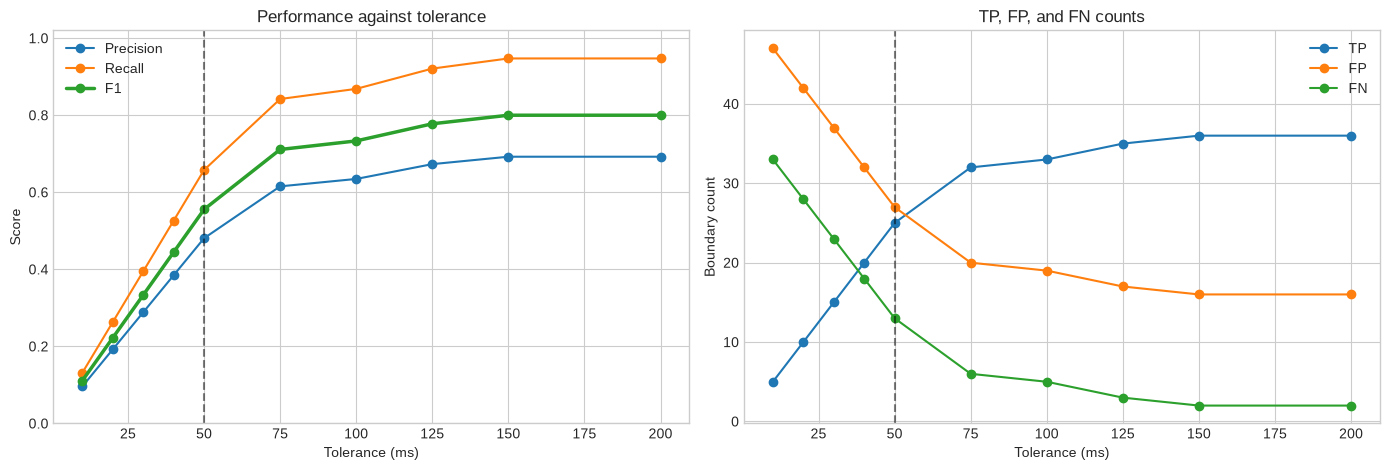

In [18]:
TOLERANCES_TO_TEST_MS = [10, 20, 30, 40, 50, 75, 100, 125, 150, 200]

sweep_rows = []
for tolerance_ms in TOLERANCES_TO_TEST_MS:
    sweep_result = evaluate_boundaries(
        ground_truth=ground_truth_boundaries,
        estimated=estimated_boundaries,
        tolerance_ms=tolerance_ms,
    )
    sweep_rows.append(sweep_result["summary"].to_dict())

tolerance_sweep = pd.DataFrame(sweep_rows)
display(
    tolerance_sweep[
        [
            "tolerance_ms",
            "true_positives",
            "false_positives",
            "false_negatives",
            "precision",
            "recall",
            "f1_score",
            "mean_absolute_error_ms",
        ]
    ].round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["precision"],
    marker="o",
    label="Precision",
)
axes[0].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["recall"],
    marker="o",
    label="Recall",
)
axes[0].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["f1_score"],
    marker="o",
    linewidth=2.5,
    label="F1",
)
axes[0].axvline(TOLERANCE_MS, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Tolerance (ms)")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.02)
axes[0].set_title("Performance against tolerance")
axes[0].legend()

axes[1].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["true_positives"],
    marker="o",
    label="TP",
)
axes[1].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["false_positives"],
    marker="o",
    label="FP",
)
axes[1].plot(
    tolerance_sweep["tolerance_ms"],
    tolerance_sweep["false_negatives"],
    marker="o",
    label="FN",
)
axes[1].axvline(TOLERANCE_MS, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Tolerance (ms)")
axes[1].set_ylabel("Boundary count")
axes[1].set_title("TP, FP, and FN counts")
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Export results

The CSV files preserve the summary, all TP pairings, all FPs, all FNs, and the tolerance sweep for use in a report or further analysis.


In [12]:
OUTPUT_DIRECTORY = Path("zerosyl_evaluation_output")
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

summary_export = results["summary"].rename_axis("metric").reset_index(name="value")
summary_export.to_csv(OUTPUT_DIRECTORY / "summary.csv", index=False)
results["matches"].to_csv(OUTPUT_DIRECTORY / "true_positive_matches.csv", index=False)
results["false_positives"].to_csv(OUTPUT_DIRECTORY / "false_positives.csv", index=False)
results["false_negatives"].to_csv(OUTPUT_DIRECTORY / "false_negatives.csv", index=False)
tolerance_sweep.to_csv(OUTPUT_DIRECTORY / "tolerance_sweep.csv", index=False)

print("Saved:")
for path in sorted(OUTPUT_DIRECTORY.glob("*.csv")):
    print(" -", path)


Saved:
 - zerosyl_evaluation_output/false_negatives.csv
 - zerosyl_evaluation_output/false_positives.csv
 - zerosyl_evaluation_output/summary.csv
 - zerosyl_evaluation_output/tolerance_sweep.csv
 - zerosyl_evaluation_output/true_positive_matches.csv
